# 05 · Emulador do CROPGRO-Soybean

Gradient boosting (scikit-learn, `HistGradientBoostingRegressor`), um modelo por saída: produtividade atingível (HWAM), dias até R1 e até R7.

- **Treino:** 2.000 combinações (hipercubo latino) dos 10 parâmetros do Morris × 40 pontos (4 por zona) × 33 safras = 2,64 milhões de safras; solo e semeadura sorteados por rodada.
- **Entradas:** 10 parâmetros, MG, solo, dia da semeadura, latitude e clima da safra (chuva, ETo, Tmax, Tmin e Rs em 0–30, 30–60 e 60–110 dias após a semeadura, e déficit total).
- **Validação:** pontos inteiros fora do treino (GroupKFold, 5 grupos de 8 pontos).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DIR = RAIZ / "resultados" / "emulador"
met = pd.read_csv(DIR / "validacao_metricas.csv")
p = pd.read_parquet(DIR / "validacao_predicoes.parquet")
met.round(3)

,saida,n,rmse,vies,r2
0,hwam,2640000,623.352,-4.921,0.758
1,r1,2640000,1.429,-0.023,0.991
2,r7,2639998,3.021,0.093,0.984


## Por safra: simulado pelo DSSAT × emulador (pontos fora do treino)

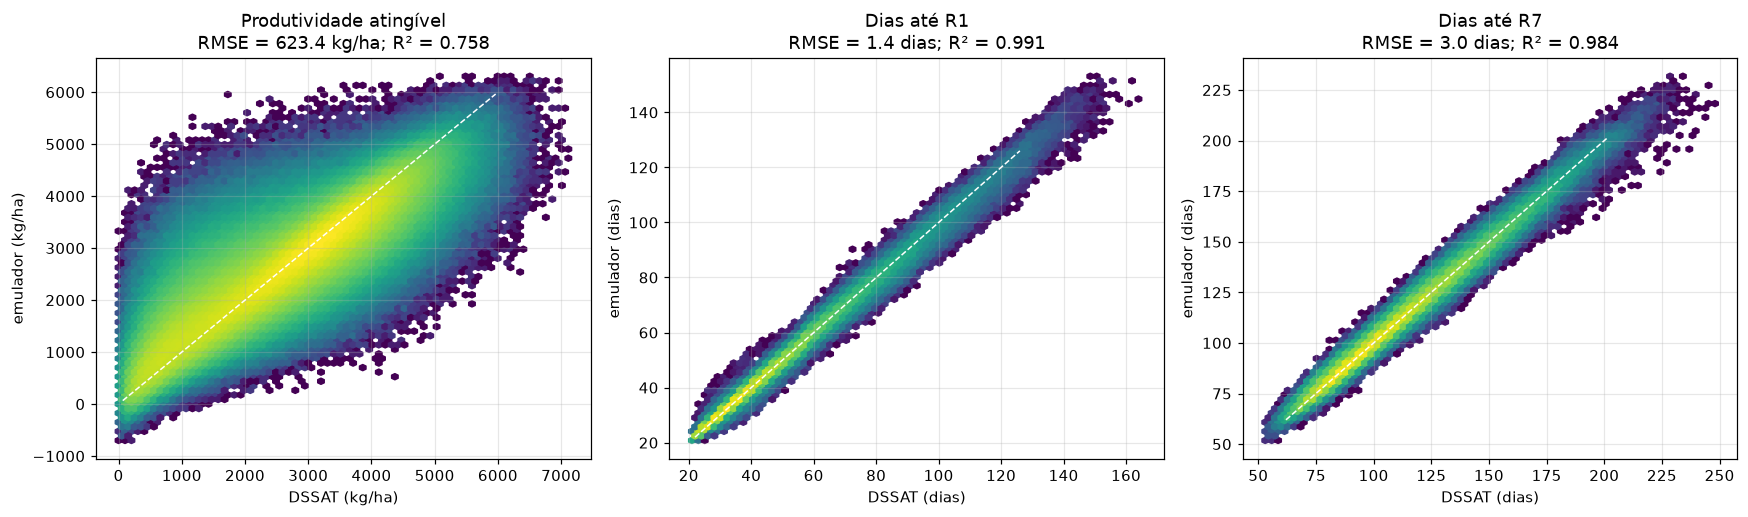

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (s, tit, un) in zip(axs, [("hwam", "Produtividade atingível", "kg/ha"), ("r1", "Dias até R1", "dias"), ("r7", "Dias até R7", "dias")]):
    q = p[[s, f"{s}_pred"]].dropna()
    hb = ax.hexbin(q[s], q[f"{s}_pred"], gridsize=70, bins="log", cmap="viridis", mincnt=1)
    lim = [q[s].quantile(.001), q[s].quantile(.999)]; ax.plot(lim, lim, "w--", lw=1)
    e = q[f"{s}_pred"] - q[s]
    ax.set_title(f"{tit}\nRMSE = {np.sqrt((e**2).mean()):.1f} {un}; R² = {1 - (e**2).sum() / ((q[s] - q[s].mean())**2).sum():.3f}")
    ax.set_xlabel(f"DSSAT ({un})"); ax.set_ylabel(f"emulador ({un})")
fig.tight_layout(); fig.savefig(DIR / "validacao_safra.png", bbox_inches="tight")

## Médias de 33 safras por combinação de parâmetros e ponto

É o nível de agregação que a calibração usa para comparar com médias do IBGE e dos experimentos.

In [3]:
g = p.groupby(["amostra", "ponto", "zona_bs"])[["hwam", "hwam_pred", "r1", "r1_pred", "r7", "r7_pred"]].mean().reset_index()
linhas = []
for s in ["hwam", "r1", "r7"]:
    e = g[f"{s}_pred"] - g[s]
    linhas.append(dict(saida=s, rmse=np.sqrt((e**2).mean()), rrmse_pct=100 * np.sqrt((e**2).mean()) / g[s].mean(),
                       vies=e.mean(), r2=1 - (e**2).sum() / ((g[s] - g[s].mean())**2).sum()))
agreg = pd.DataFrame(linhas).round(3); agreg.to_csv(DIR / "validacao_medias.csv", index=False); agreg

,saida,rmse,rrmse_pct,vies,r2
0,hwam,299.293,11.446,-4.921,0.915
1,r1,0.954,2.309,-0.023,0.996
2,r7,1.609,1.524,0.093,0.995


## Erro por zona (produtividade, por safra)

In [4]:
z = p.assign(e=p.hwam_pred - p.hwam).groupby("zona_bs").agg(rmse=("e", lambda x: np.sqrt((x**2).mean())), vies=("e", "mean"),
                                                           media=("hwam", "mean"))
z["rrmse_pct"] = 100 * z.rmse / z.media
z.round(1)

,rmse,vies,media,rrmse_pct
zona_bs,,,,
1.0,324.6,22.1,3144.1,10.3
2.0,344.9,-38.8,3326.1,10.4
3.0,751.8,-432.4,3450.7,21.8
4.0,396.8,-18.0,2224.1,17.8
5.0,538.2,-28.1,2292.3,23.5
6.0,730.9,59.2,2224.6,32.9
7.0,702.0,283.9,1364.2,51.5
8.0,762.3,191.8,2684.1,28.4
9.0,790.1,-37.9,2671.7,29.6


## Variação entre anos: correlação safra a safra dentro de cada combinação

In [5]:
r_ano = p.groupby(["amostra", "ponto"]).apply(lambda x: x.hwam.corr(x.hwam_pred))
print(f"correlação interanual (mediana entre combinações): {r_ano.median():.2f} | p10 = {r_ano.quantile(.1):.2f} | p90 = {r_ano.quantile(.9):.2f}")

correlação interanual (mediana entre combinações): 0.67 | p10 = 0.37 | p90 = 0.83


## Emulador em duas etapas para a produtividade

Com janelas fixas após a semeadura, o emulador de produtividade erra muito nas zonas secas, porque o ciclo varia de 75 a 170 dias com os parâmetros. Na versão em duas etapas:

1. o emulador de fenologia prevê R1 e R7 (previsões fora do treino, como na calibração);
2. o clima é resumido nas fases S–R1, R1–R5 e R5–R7 (R5 ≈ R1 + 0,4 (R7 − R1));
3. um balde (capacidade = água disponível na zona de raiz, dada pelo solo, pelo fator de água disponível e pela profundidade de raiz; Kc de 0,5 a 1,05) dá a razão ETa/ETc em cada fase;
4. o emulador de produtividade usa essas variáveis (`src/emulador.py`, `src/validar_emulador_fen.py`).

In [6]:
a = pd.read_parquet(DIR / "validacao_predicoes.parquet"); b = pd.read_parquet(DIR / "validacao_predicoes_fen.parquet")
def resumo(q):
    e = q.hwam_pred - q.hwam
    z = q.assign(e=e).groupby("zona_bs").agg(rmse=("e", lambda x: np.sqrt((x**2).mean())), vies=("e", "mean"), media=("hwam", "mean"))
    g = q.groupby(["amostra", "ponto"])[["hwam", "hwam_pred"]].mean(); eg = g.hwam_pred - g.hwam
    return (100 * z.rmse / z.media), z.vies, np.sqrt((e**2).mean()), 100 * np.sqrt((eg**2).mean()) / g.hwam.mean()
ra, va, sa, ma = resumo(a); rb, vb, sb, mb = resumo(b)
print(f"RMSE por safra: {sa:.0f} → {sb:.0f} kg/ha | RMSE relativo nas médias de 33 safras: {ma:.1f}% → {mb:.1f}%")
pd.DataFrame({"rrmse_%_janelas_fixas": ra, "rrmse_%_duas_etapas": rb, "vies_janelas_fixas": va, "vies_duas_etapas": vb}).round(1)

RMSE por safra: 623 → 330 kg/ha | RMSE relativo nas médias de 33 safras: 11.4% → 5.2%


,rrmse_%_janelas_fixas,rrmse_%_duas_etapas,vies_janelas_fixas,vies_duas_etapas
zona_bs,,,,
1.0,10.3,7.7,22.1,30.0
2.0,10.4,7.5,-38.8,-5.5
3.0,21.8,10.9,-432.4,-146.6
4.0,17.8,12.0,-18.0,4.6
5.0,23.5,13.0,-28.1,-24.1
6.0,32.9,16.4,59.2,22.0
7.0,51.5,23.6,283.9,68.4
8.0,28.4,14.3,191.8,46.2
9.0,29.6,14.6,-37.9,-26.6


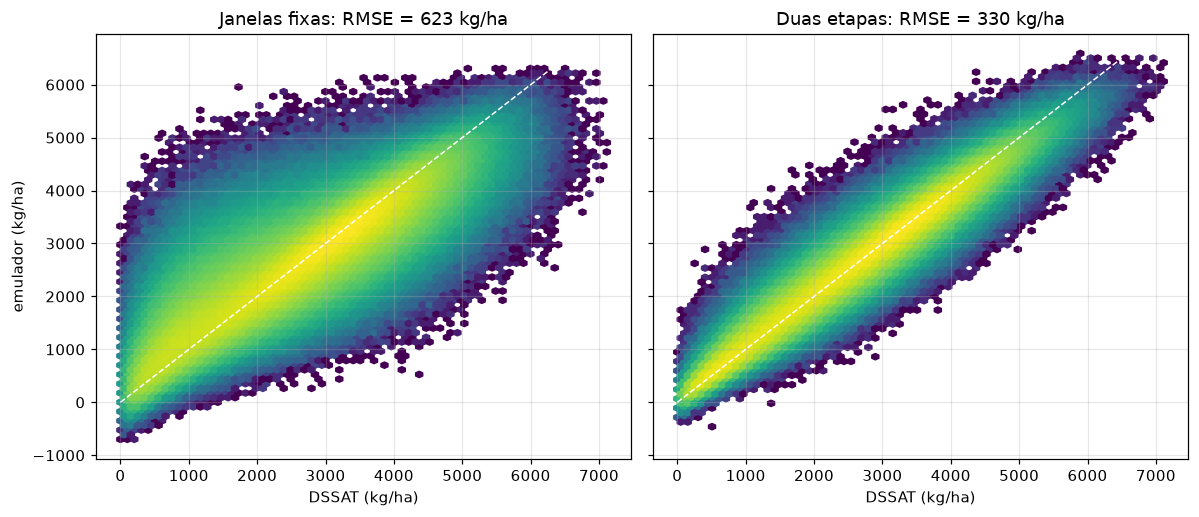

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, (q, tit) in zip(axs, [(a, "Janelas fixas"), (b, "Duas etapas")]):
    ax.hexbin(q.hwam, q.hwam_pred, gridsize=70, bins="log", cmap="viridis", mincnt=1); ax.plot([0, 6500], [0, 6500], "w--", lw=1)
    e = q.hwam_pred - q.hwam; ax.set_title(f"{tit}: RMSE = {np.sqrt((e**2).mean()):.0f} kg/ha")
    ax.set_xlabel("DSSAT (kg/ha)")
axs[0].set_ylabel("emulador (kg/ha)")
fig.tight_layout(); fig.savefig(DIR / "validacao_duas_etapas.png", bbox_inches="tight")